In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier

from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


In [2]:
df = pd.read_csv("diabetes.csv")

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

print("First Five Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


First Five Records:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Dataset Shape:
(768, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   Ski

In [3]:
# Remove duplicate records
df.drop_duplicates(inplace=True)

# Automatically identify the target column
target_candidates = [
    "outcome",
    "diabetes",
    "diabetes_binary",
    "target",
    "class"
]

target_column = None

for col in df.columns:

    if col.lower() in target_candidates:
        target_column = col
        break

# If target column is not identified automatically,
# ask the user to enter its name.
if target_column is None:

    print("\nAvailable Columns:", list(df.columns))

    target_column = input("Enter target column name: ").strip()

    if target_column not in df.columns:
        raise ValueError("Target column not found in dataset.")

print("\nTarget Column:", target_column)

# Remove rows having missing target values
df.dropna(subset=[target_column], inplace=True)

# Separate target variable
y = df[target_column]

# Select numerical input features
X = df.drop(columns=[target_column])

X = X.select_dtypes(include=np.number)

# Remove unnecessary ID columns if available
id_columns = [
    "id",
    "patientid",
    "patient_id"
]

X = X.drop(
    columns=[
        col for col in X.columns
        if col.lower() in id_columns
    ],
    errors="ignore"
)

# Convert invalid values into NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Handle zero values in common Pima diabetes columns
missing_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in X.columns:

    if col.lower() in [c.lower() for c in missing_zero_columns]:
        X.loc[X[col] == 0, col] = np.nan

# Remove columns containing only missing values
X.dropna(axis=1, how="all", inplace=True)

# Remove constant features
X = X.loc[:, X.nunique(dropna=True) > 1]

if X.shape[1] == 0:
    raise ValueError("No useful numerical features found.")

print("\nSelected Features:")
print(list(X.columns))

print("\nFeatures After Preprocessing:")
print(X.head())

print("\nTarget Distribution:")
print(y.value_counts())




Target Column: Outcome

Selected Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'Pedigree', 'Age']

Features After Preprocessing:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0      NaN  33.6   
1            1     85.0           66.0           29.0      NaN  26.6   
2            8    183.0           64.0            NaN      NaN  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   Pedigree  Age  
0     0.627   50  
1     0.351   31  
2     0.672   32  
3     0.167   21  
4     2.288   33  

Target Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [4]:
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("\nTarget Class Mapping:")

for i, label in enumerate(label_encoder.classes_):
    print(i, "=", label)

# This practical expects binary diabetes classification
if len(label_encoder.classes_) != 2:
    raise ValueError(
        "This practical expects exactly two target classes."
    )

print("\nTarget Encoding Completed Successfully!")



Target Class Mapping:
0 = 0
1 = 1

Target Encoding Completed Successfully!


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(pd.Series(y_train).value_counts())



Training Data Shape: (614, 8)
Testing Data Shape: (154, 8)

Training Class Distribution:
0    400
1    214
Name: count, dtype: int64


In [6]:
# Create preprocessing and KNN pipeline
# The KNN model will be added in the next cell.

preprocessor = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# Fit preprocessing on training data only
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform testing data using the same training parameters
X_test_scaled = preprocessor.transform(X_test)

print("\nFeature Scaling Completed Successfully!")

print("\nFirst Five Scaled Training Records:")
print(X_train_scaled[:5])



Feature Scaling Completed Successfully!

First Five Scaled Training Records:
[[-0.85135507 -1.05642747 -0.82674004 -1.91818693 -1.20336073 -0.76969431
   0.31079384 -0.79216928]
 [ 0.35657564  0.14439907  0.47777235 -0.22987447 -1.47019479 -0.41771394
  -0.11643851  0.56103382]
 [-0.5493724  -0.55608308 -1.15286813  1.23332967 -0.55533518  0.35957603
  -0.76486207 -0.70759409]
 [-0.85135507  0.81152492 -1.31593218 -0.00476614 -0.16143729 -0.40304809
   0.26231357 -0.36929331]
 [-1.15333775 -0.88964601 -0.66367599  1.12077551 -0.41556496  1.78216334
  -0.33762972 -0.96131967]]


In [7]:
# Take K value from the user
k_input = input("\nEnter value of K (Press Enter for 5): ")

if k_input.strip() == "":
    k = 5
else:
    k = int(k_input)

# K cannot exceed the number of training records
if k < 1 or k > len(X_train):
    raise ValueError("K must be between 1 and number of training records.")

# Create KNN classifier
knn = KNeighborsClassifier(
    n_neighbors=k,
    metric="euclidean",
    weights="uniform"
)

# Train the KNN model
knn.fit(X_train_scaled, y_train)

print("\nKNN Model Trained Successfully!")

# Predict testing data
y_pred = knn.predict(X_test_scaled)

print("\nFirst 10 Actual Values:")
print(y_test[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])




Enter value of K (Press Enter for 5):  5



KNN Model Trained Successfully!

First 10 Actual Values:
[0 0 0 1 0 0 1 1 0 0]

First 10 Predicted Values:
[1 0 0 1 0 0 0 1 0 1]


In [8]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

# Extract individual values
tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)


# ==============================================================
# CELL 9: CALCULATE ACCURACY AND ERROR RATE
#
# Purpose:
# Calculate the overall correctness of the model.
#
# Accuracy:
# Number of correct predictions / Total predictions.
#
# Error Rate:
# Number of incorrect predictions / Total predictions.
#
# ==============================================================

accuracy = accuracy_score(y_test, y_pred)

error_rate = 1 - accuracy

print("\nAccuracy:", round(accuracy, 4))

print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

print("Error Rate:", round(error_rate, 4))

print("Error Percentage:", round(error_rate * 100, 2), "%")



Confusion Matrix:
[[83 17]
 [21 33]]

True Negative (TN): 83
False Positive (FP): 17
False Negative (FN): 21
True Positive (TP): 33

Accuracy: 0.7532
Accuracy Percentage: 75.32 %
Error Rate: 0.2468
Error Percentage: 24.68 %


In [9]:
precision = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

print("\nPrecision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1 Score:", round(f1, 4))



Precision: 0.66
Recall: 0.6111
F1 Score: 0.6346


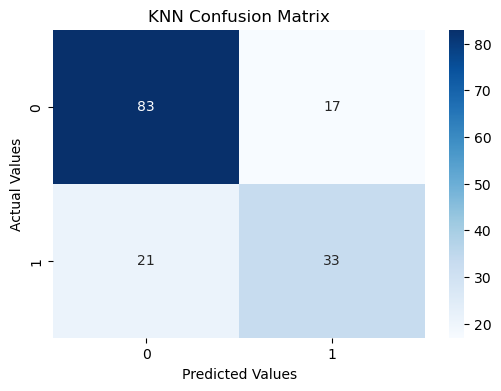

In [10]:
class_names = [
    str(label) for label in label_encoder.classes_
]

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.title("KNN Confusion Matrix")

plt.show()


In [11]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=class_names,
        zero_division=0
    )
)



Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [12]:
results = pd.DataFrame({

    "Evaluation Metric": [
        "Accuracy",
        "Error Rate",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Score": [
        accuracy,
        error_rate,
        precision,
        recall,
        f1
    ]

})

print("\nFINAL KNN MODEL PERFORMANCE:")

print(results.to_string(index=False))

print("\nK Value Used:", k)

print("Algorithm: K-Nearest Neighbors")

print("Model Evaluation Completed Successfully!")


FINAL KNN MODEL PERFORMANCE:
Evaluation Metric    Score
         Accuracy 0.753247
       Error Rate 0.246753
        Precision 0.660000
           Recall 0.611111
         F1 Score 0.634615

K Value Used: 5
Algorithm: K-Nearest Neighbors
Model Evaluation Completed Successfully!
